In [190]:
import matplotlib.pyplot as plt
import numpy as np

In [191]:
# this project has an agent start at the top left [0][0] of a map, and the agent wants to collect apples (1) and avoid spikes (2)
"""
map = [[0, 1, 0, 0, 0, 0, 2, 0, 0, 2],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [2, 0, 0, 1, 2, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [2, 0, 0, 0, 0, 0, 1, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 2, 0, 0, 0],
       [2, 0, 0, 0, 0, 0, 0, 0, 0, 1]]

map = [[0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]]
"""
map = [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]]
# note: 30 steps should be enough to get all the apples (def possible in 26)

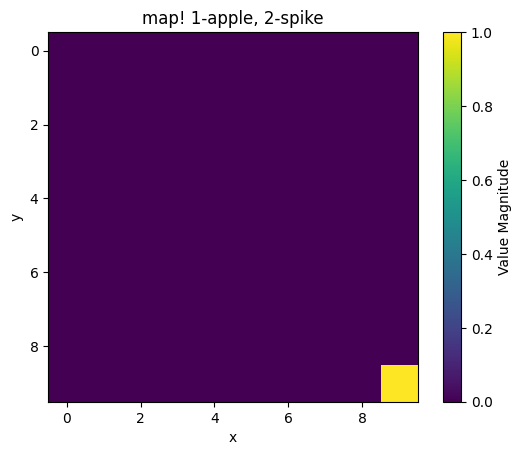

In [192]:
plt.imshow(map, cmap='viridis', interpolation='nearest')
plt.colorbar(label='Value Magnitude')
plt.title('map! 1-apple, 2-spike')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [193]:
# all the functions:

# returns the starting state and map
def reset():
    map = [[0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]]
    return [0, 0], map, 0

# the environment maps a state and an action to another state
# in this case, the action is a number 0-4 inclusive. 0-north, 1-east, 2-south, 3-west
# the state is an array of 2 numbers representing the cartesian coordinate of where the agent is
def env(state, action, map):
    # move the agent
    if action == 0:
        state[0] -= 1
    if action == 1:
        state[1] += 1
    if action == 2:
        state[0] += 1
    if action == 3:
        state[1] -= 1
    
    # if the agent is in an invalid location (outside the bounds of the map), move the agent back
    if state[0] < 0:
        state[0] = 0
    if state[0] > 9:
        state[0] = 9
    if state[1] < 0:
        state[1] = 0
    if state[1] > 9:
        state[1] = 9
    
    return state, map

# the reward function takes in the state and outputs whether this is a terminal state, whether it is a truncated state, and the reward
def reward_func(state, map, num_apples):
    reward = 0
    terminal = False
    truncated = False

    if map[state[0]][state[1]] == 1:
        reward += 1
        map[state[0]][state[1]] = 0 # when an apple has been collected, remove the apple from the map
    elif map[state[0]][state[1]] == 2:
        terminal = True
        reward -= 100
    
    if num_apples == 1:
        truncated = True
    
    return reward, terminal, truncated

# takes in an array of values and applies the softmax algorithm. It returns an array of values corresponding to the probability of each value
def softmax(values):
    sum = np.sum(np.exp(values))
    values = np.exp(values)
    values /= sum
    return values

def choose_action(probabilities):
    return np.random.choice([0, 1, 2, 3], 1, p=probabilities)


In [212]:
state = [0, 0]
num_apples = 0

# hyperparamaters
lr = 0.1
gamma = 0.5
epochs = 100000

# the state is the first two inputs and the action is the last input
# for example, the quality of moving east at position (4, 8) is Q[4][8][1], where 0-north, 1-east, 2-south, 3-west
Q = np.zeros((10, 10, 4))

In [213]:
# training loop
state, map, num_apples = reset()

episode = 0
apple_counts = []
for t in range(epochs):
    action = choose_action(softmax(Q[state[0]][state[1]]))
    # get the quality for the current state and chosen action (for a later computation)
    q = Q[state[0]][state[1]][action]
    r = state[0] # just for storing for later
    c = state[1]

    # now that an action has been chosen, update the environment and state
    state, map = env(state, action, map)
    num_apples += map[state[0]][state[1]]

    # observe the reward associated with the chosen action
    reward, terminal, truncated = reward_func(state, map, num_apples)
    
    if terminal or truncated:
        episode = 0
        apple_counts.append(num_apples)
        state, map, num_apples = reset()
        new_Q = ((1 - lr) * q) + (lr * (reward + (gamma * np.max(Q[state[0]][state[1]]))))
        Q[r][c][action] = new_Q
    elif episode >= 40:
        apple_counts.append(num_apples)
        episode = 0
        state, map, num_apples = reset()
        Q[r][c][action] = 0
    else:
        episode += 1
        new_Q = ((1 - lr) * q) + (lr * (reward + (gamma * np.max(Q[state[0]][state[1]]))))
        Q[r][c][action] = new_Q

In [214]:
print(np.max(apple_counts))

1


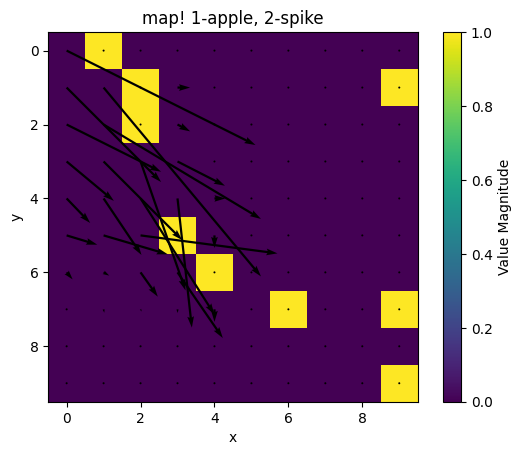

'\nwhile num_apples < 6:\n    action = choose_action(softmax(Q[state[0]][state[1]]))\n    state, map = env(state, action, map)\n    if map[state[0]][state[1]] == 1:\n        num_apples += 1\n        map[state[0]][state[1]] = 0\n'

In [215]:
# now that we have a Q table, let's observe our agent collect the apples! (and maybe find a way to visualize the choices)
state, map, num_apples = reset()

X, Y = np.meshgrid(np.linspace(0, 9, 10), np.linspace(0, 9, 10))
vec_X = np.zeros((10, 10))
vec_Y = np.zeros((10, 10))
for x in range(10):
    for y in range(10):
        vec_X[y][x] = Q[y][x][1] + Q[y][x][3]
        vec_Y[y][x] = -Q[y][x][0] - Q[y][x][2]
U = vec_X
V = vec_Y
vec = Q[:][:]
plt.quiver(X, Y, U, V)

plt.imshow(map, cmap='viridis', interpolation='nearest')
plt.colorbar(label='Value Magnitude')
plt.title('map! 1-apple, 2-spike')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

"""
while num_apples < 6:
    action = choose_action(softmax(Q[state[0]][state[1]]))
    state, map = env(state, action, map)
    if map[state[0]][state[1]] == 1:
        num_apples += 1
        map[state[0]][state[1]] = 0
"""